In [101]:
import torch, torchvision, numpy as np, matplotlib.pyplot as plt
from sympy.parsing.sympy_parser import null
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import transforms, datasets, models
import torch.nn as nn, torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix
from torchvision import datasets, transforms
import seaborn as sns
from collections import Counter
from PIL import Image
from sklearn.model_selection import train_test_split
import torchvision.transforms as T

In [102]:
print("Загрузка данных...")
train_full = datasets.CIFAR10(root="data", train=True,  download=True,
                              transform=T.ToTensor())
test_full  = datasets.CIFAR10(root="data", train=False, download=True,
                              transform=T.ToTensor())

Загрузка данных...


In [103]:
print("=== train_full ===")
print(f"Количество изображений: {len(train_full)}")

print("\n=== test_full ===")
print(f"Количество изображений: {len(test_full)}")

=== train_full ===
Количество изображений: 50000

=== test_full ===
Количество изображений: 10000


In [104]:
def show_im(CLASSES, labels, images):
    # По 5 примеров на каждый класс
    samples_per_class = 8
    cell = 0.9

    fig, axes = plt.subplots(
        nrows=len(CLASSES),
        ncols=samples_per_class,
        figsize=(samples_per_class * cell, len(CLASSES) * cell)
    )

    for class_idx, class_name in enumerate(CLASSES):
        # индексы всех картинок этого класса
        idxs = (labels == class_idx).nonzero(as_tuple=True)[0]
        # первые 5
        chosen = idxs[:samples_per_class]

        for j, idx in enumerate(chosen):
            ax = axes[class_idx, j]
            img = images[idx]
            ax.imshow(img.permute(1, 2, 0).numpy(), interpolation='nearest')
            ax.set_xticks([])
            ax.set_yticks([])
            if j == 0:
                ax.set_ylabel(class_name, fontsize=11, rotation=0,
                              labelpad=40, va='center')

    plt.suptitle("CIFAR-10: 5 примеров на класс", fontsize=14)
    plt.tight_layout()
    plt.show()

In [105]:
print("Разделяем данные")

# Правильное разделение train на train + val (45 000 / 5 000)
# Используем стратификацию, чтобы классы были равномерны
idx_train, idx_val = train_test_split(
    np.arange(len(train_full)),
    test_size=5000,
    stratify=train_full.targets,
    random_state=42
)

train_data = Subset(train_full, idx_train) # 45 000
val_data   = Subset(train_full, idx_val)   # 5 000
test_data  = test_full                     # 10 000

print(f"Train: {len(train_data)}, Val: {len(val_data)}, Test: {len(test_data)}")

Разделяем данные
Train: 45000, Val: 5000, Test: 10000


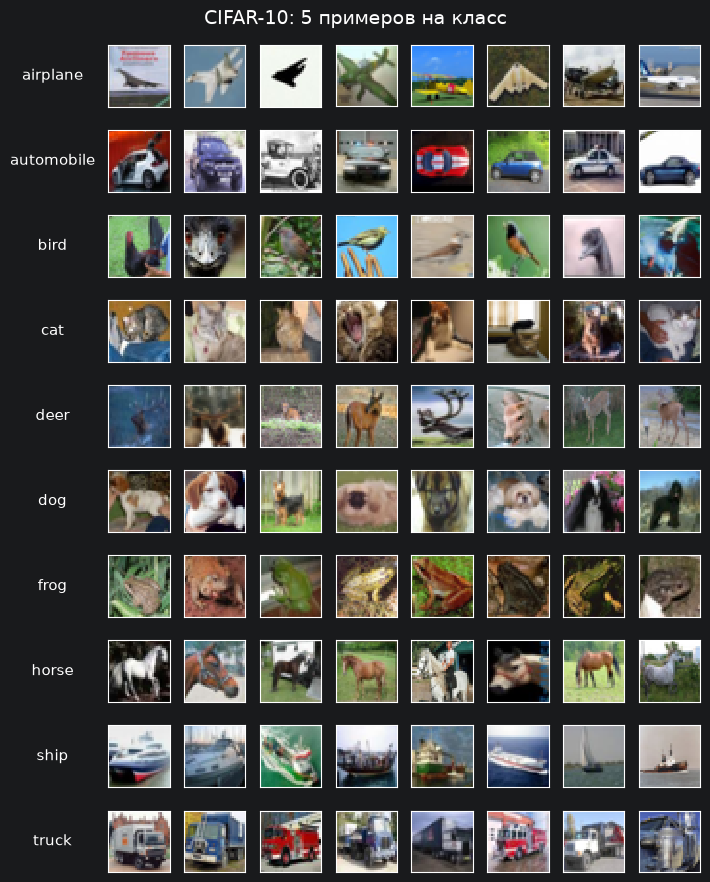

In [106]:
images = torch.stack([img for img, _ in test_full])
labels = torch.tensor([label for _, label in test_full])

# Классы CIFAR-10
CLASSES = ('airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

show_im(CLASSES, labels, images)

In [107]:
def balans(data):
    print("Проводим анализ датасета")

    # Достаём список меток и список имён классов ---
    if hasattr(data, "indices") and hasattr(data, "dataset"):
        # Subset из random_split
        base = data.dataset
        if hasattr(base, "targets"):
            all_lb = base.targets
        else:
            all_lb = [y for _, y in base.samples]
        lb = [all_lb[i] for i in data.indices]
        class_names = base.classes

    elif hasattr(data, "targets"):
        # CIFAR10 / MNIST напрямую
        lb = list(data.targets)
        class_names = data.classes

    elif hasattr(data, "samples"):
        # ImageFolder напрямую
        lb = [y for _, y in data.samples]
        class_names = data.classes

    else:
        lb = [int(y) for _, y in data]
        class_names = getattr(data, "classes", [str(i) for i in range(max(lb)+1)])

    cn = Counter(lb)

    s = sum(cn.values())

    print(f"Число изображений: {s}")

    # красивый вывод с именами классов
    for idx, name in enumerate(class_names):
        print(f"{name:>10}: {cn[idx]:>6}  ({cn[idx]/len(lb):.1%})")

In [108]:
def size_im(data, max_n=None):
    # Возвращает список (height, width, channels) для изображений датасета

    if hasattr(data, "indices") and hasattr(data, "dataset"):
        base = data.dataset
        if hasattr(base, "data") and getattr(base.data, "ndim", 0) == 4:
            _, H, W, C = base.data.shape
            return [(H, W, C)] * len(data.indices)     # все одинаковые
        paths = [base.samples[i][0] for i in data.indices]
        return [Image.open(p).size[::-1] + (len(Image.open(p).getbands()),)
                for p in paths]

    if hasattr(data, "data") and getattr(data.data, "ndim", 0) == 4:
        _, H, W, C = data.data.shape
        return [(H, W, C)] * len(data)

    if hasattr(data, "samples"):
        sizes = []
        for p, _ in data.samples:
            with Image.open(p) as im:
                sizes.append((im.height, im.width, len(im.getbands())))
        return sizes

    if max_n is None:
        max_n = len(data)
    sizes = []
    for i in range(min(max_n, len(data))):
        x, _ = data[i]
        sizes.append((x.shape[-2], x.shape[-1], x.shape[-3]))
    return sizes

In [109]:
balans(train_full)

Проводим анализ датасета
Число изображений: 50000
  airplane:   5000  (10.0%)
automobile:   5000  (10.0%)
      bird:   5000  (10.0%)
       cat:   5000  (10.0%)
      deer:   5000  (10.0%)
       dog:   5000  (10.0%)
      frog:   5000  (10.0%)
     horse:   5000  (10.0%)
      ship:   5000  (10.0%)
     truck:   5000  (10.0%)


In [110]:
balans(test_full)

Проводим анализ датасета
Число изображений: 10000
  airplane:   1000  (10.0%)
automobile:   1000  (10.0%)
      bird:   1000  (10.0%)
       cat:   1000  (10.0%)
      deer:   1000  (10.0%)
       dog:   1000  (10.0%)
      frog:   1000  (10.0%)
     horse:   1000  (10.0%)
      ship:   1000  (10.0%)
     truck:   1000  (10.0%)


In [111]:
sizes = size_im(train_data)
print("Уникальные размеры:", set(sizes))

Уникальные размеры: {(32, 32, 3)}


In [112]:
balans(train_data)

Проводим анализ датасета
Число изображений: 45000
  airplane:   4500  (10.0%)
automobile:   4500  (10.0%)
      bird:   4500  (10.0%)
       cat:   4500  (10.0%)
      deer:   4500  (10.0%)
       dog:   4500  (10.0%)
      frog:   4500  (10.0%)
     horse:   4500  (10.0%)
      ship:   4500  (10.0%)
     truck:   4500  (10.0%)


In [113]:
balans(val_data)

Проводим анализ датасета
Число изображений: 5000
  airplane:    500  (10.0%)
automobile:    500  (10.0%)
      bird:    500  (10.0%)
       cat:    500  (10.0%)
      deer:    500  (10.0%)
       dog:    500  (10.0%)
      frog:    500  (10.0%)
     horse:    500  (10.0%)
      ship:    500  (10.0%)
     truck:    500  (10.0%)


In [114]:
balans(test_data)

Проводим анализ датасета
Число изображений: 10000
  airplane:   1000  (10.0%)
automobile:   1000  (10.0%)
      bird:   1000  (10.0%)
       cat:   1000  (10.0%)
      deer:   1000  (10.0%)
       dog:   1000  (10.0%)
      frog:   1000  (10.0%)
     horse:   1000  (10.0%)
      ship:   1000  (10.0%)
     truck:   1000  (10.0%)
